# Practical 3 — Linear Regression and Gradient Descent from Scratch

**Lectures:** 5. Machine Learning Algorithms · 6. Linear Regression

You will implement **simple (univariate) linear regression** trained by **batch gradient
descent**, using only NumPy, and then check it against the closed-form solution and scikit-learn's
`LinearRegression`. The notation follows the lectures:

* hypothesis: $h_\theta(x) = \theta_0 + \theta_1 x$
* cost (mean squared error): $J(\theta_0,\theta_1) = \dfrac{1}{2m}\sum_{i=1}^{m}\big(h_\theta(x^{(i)}) - y^{(i)}\big)^2$
* gradient descent, repeated until convergence, with learning rate $\alpha$:
  $\theta_0 := \theta_0 - \alpha\dfrac{1}{m}\sum_{i}\big(h_\theta(x^{(i)}) - y^{(i)}\big)$,
  $\quad\theta_1 := \theta_1 - \alpha\dfrac{1}{m}\sum_{i}\big(h_\theta(x^{(i)}) - y^{(i)}\big)x^{(i)}$

(both parameters are updated **simultaneously**).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

## 1. A synthetic dataset where we know the truth (≈10 min)
We generate $m = 100$ points from $y = 4 + 3x + \varepsilon$ with Gaussian noise $\varepsilon$.
A correct learner should recover $\theta_0 \approx 4$ and $\theta_1 \approx 3$.

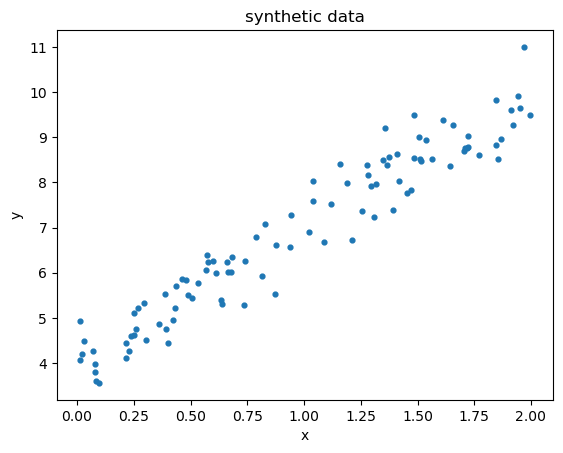

In [14]:
m = 100
x = rng.uniform(0, 2, m)
y = 4 + 3 * x + rng.normal(0, 0.5, m)

plt.scatter(x, y, s=12); plt.xlabel("x"); plt.ylabel("y"); plt.title("synthetic data"); plt.show()

## 2. Hypothesis and cost function (≈15 min)
**TODO 2.1** Implement `predict(theta0, theta1, x)` and `cost(theta0, theta1, x, y)` using
vectorised NumPy (no loops). Check: `cost(4, 3, x, y)` should be close to half the noise variance (≈ 0.125).

In [7]:
def predict(theta0, theta1, x):
    return theta0 + theta1*np.array(x)

def cost(theta0, theta1, x, y):
    m = len(y)
    return 1/(2*m) * np.sum((predict(theta0, theta1, x) - y)**2)
    

print(cost(0, 0, x, y), cost(4, 3, x, y))

26.450708591308203 0.1224218494943369


Close to 0.125 (0.122) so check passes implementation likely to be correct

**TODO 2.2 — Visualise the cost surface.** Evaluate $J$ on a grid of
$\theta_0 \in [-2, 10]$, $\theta_1 \in [-3, 9]$ and draw a contour plot
(`plt.contour` with `levels=np.logspace(-1, 2.5, 20)`). Where is the minimum?
Why is there exactly one?

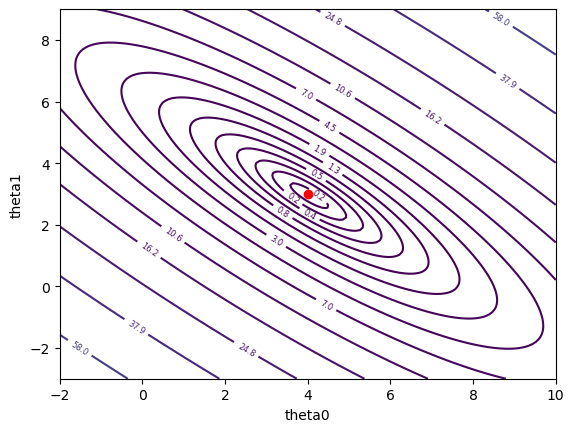

In [ ]:
t0_grid, t1_grid = np.meshgrid(np.linspace(-2, 10, 150), np.linspace(-3, 9, 150))

# Evaluate J on the created meshgrid
grid_cost = np.vectorize(lambda theta0, theta1: cost(theta0, theta1, x, y))
J = grid_cost(t0_grid, t1_grid)

contourPlot = plt.contour(t0_grid, t1_grid, J, levels=np.logspace(-1, 2.5, 20))
plt.xlabel("theta0")
plt.ylabel("theta1")
plt.plot(4,3,"ro")
plt.clabel(contourPlot, fontsize=6)
plt.show()

Minimum is at theta0 = 4 and theta1 = 3, as shown by the red dot. There has to be exactly one minimum there as that is the chosen values from our y. Therefore that must be the minimum cost since the error is normal and thus symmetrical.

## 3. Batch gradient descent (≈30 min)
**TODO 3.1** Complete `gradient_descent`. It should start from $\theta_0 = \theta_1 = 0$,
perform `n_iters` simultaneous updates and return the final parameters together with the
history of costs and parameters (so we can plot them).

In [23]:
def gradient_descent(x, y, alpha=0.1, n_iters=1000):
    theta0, theta1 = 0.0, 0.0
    cost_history, theta_history = [], []
    for _ in range(n_iters):
        newtheta0 = theta0 - ((alpha/len(y)) * (np.sum(predict(theta0, theta1, x) - y)))
        newtheta1 = theta1 - ((alpha/len(y)) * (np.sum((predict(theta0, theta1, x) - y)*x)))
        theta0, theta1 = newtheta0, newtheta1

        cost_history.append(cost(theta0, theta1, x, y))
        theta_history.append((theta0, theta1))
    return theta0, theta1, np.array(cost_history), np.array(theta_history)

theta0, theta1, J_hist, th_hist = gradient_descent(x, y, alpha=0.1, n_iters=1000)
print(f"theta0 = {theta0:.3f}, theta1 = {theta1:.3f}, final cost = {J_hist[-1]:.4f}")

theta0 = 4.036, theta1 = 2.943, final cost = 0.1228


**TODO 3.2** Plot (a) the cost against iteration number and (b) the path taken by
$(\theta_0, \theta_1)$ over the contour plot from 2.2, and (c) the fitted line over the data.

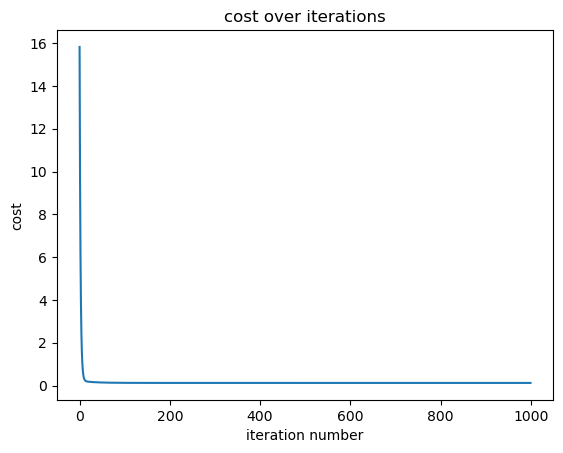

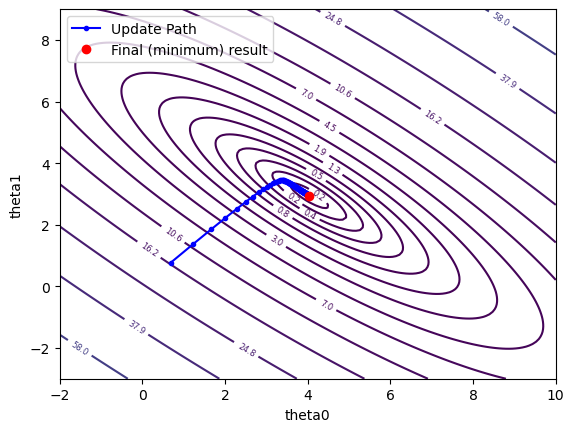

In [52]:
plt.plot(np.arange(1000), J_hist); plt.xlabel("iteration number"); plt.ylabel("cost"); plt.title("cost over iterations"); plt.show()

contourPlot = plt.contour(t0_grid, t1_grid, J, levels=np.logspace(-1, 2.5, 20)); plt.xlabel("theta0"); plt.ylabel("theta1")
plt.plot(np.transpose(th_hist)[0], np.transpose(th_hist)[1], marker='.', linestyle='-', color='b', label='Update Path'); plt.clabel(contourPlot, fontsize=6)
plt.plot(th_hist[-1, 0], th_hist[-1, 1], "ro", label="Final (minimum) result")
plt.legend(); plt.show()

**TODO 3.3 — The learning rate $\alpha$ (a hyperparameter).** Run gradient descent for
200 iterations with $\alpha \in \{0.001, 0.01, 0.1, 0.5, 1.0\}$ and plot the cost curves on
one set of axes (log scale). Which values are too small, which converge well, and which diverge?

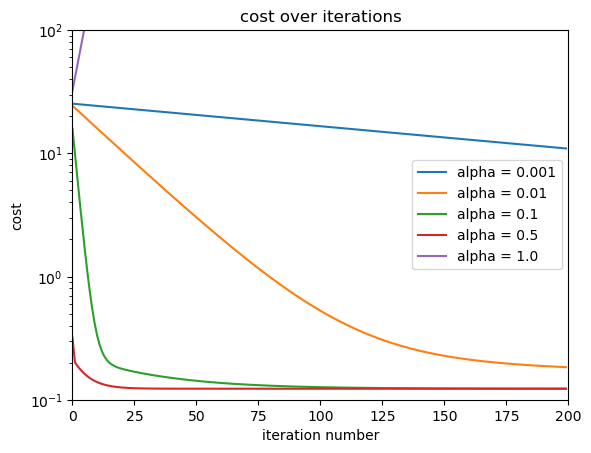

In [62]:
for alpha in [0.001, 0.01, 0.1, 0.5, 1.0]:
    theta0, theta1, J_hist, th_hist = gradient_descent(x, y, alpha, n_iters=200)
    plt.plot(np.arange(200), J_hist, label=f"alpha = {alpha}")

plt.yscale("log"); plt.ylim(0.1, 100); plt.xlim(0, 200)
plt.xlabel("iteration number"); plt.ylabel("cost"); plt.title("cost over iterations"); plt.legend()
plt.show()

Here the alpha = 1.0 line continues upwards, increasing cost into multiple magintudes

The 0.001 and 0.01 alpha are too small as they reach a small cost too slowly compared to the others. The 0.1 and 0.5 alphas converge well with 0.5 being the fastest to minimise the cost. The 0.1 alpha diverges and continues to increase towards infinity making it the worst choice.

## 4. Checking against the closed form and scikit-learn (≈10 min)
For one feature the least-squares solution has a closed form:
$\theta_1 = \dfrac{\sum_i (x^{(i)}-\bar x)(y^{(i)}-\bar y)}{\sum_i (x^{(i)}-\bar x)^2}$, $\;\theta_0 = \bar y - \theta_1 \bar x$.

**TODO 4.1** Compute it, and fit `sklearn.linear_model.LinearRegression`. Do all three agree?

In [64]:
from sklearn.linear_model import LinearRegression

def least_squares_sol(x, y):
    xmean = np.mean(x)
    ymean = np.mean(y)
    theta1 = np.sum((x-xmean)*(y-ymean))/np.sum((x-xmean)**2)
    theta0 = ymean - theta1*xmean
    return theta0, theta1

ls_theta0, ls_theta1 = least_squares_sol(x, y)

model = LinearRegression()
model.fit(x.reshape(-1, 1), y)
lr_theta0 = model.intercept_
lr_theta1 = model.coef_[0]

pd.DataFrame(np.array([
    [4, 3],
    [round(ls_theta0, 3), round(ls_theta1, 3)],
    [round(lr_theta0, 3), round(lr_theta1, 3)]
    ]), columns=np.array(["Theta 0", "Theta 1"]), index=np.array(["Actual", "Least Squares", "Linear Regression"]))

,Theta 0,Theta 1
Actual,4.000,3.000
Least Squares,4.036,2.943
Linear Regression,4.036,2.943


The least squares and linear regression agree but the actual is still a bit different

## 5. Real data: predicting house value from income (≈35 min)
Back to California housing. We use a single feature, `median_income` (in \$10 000s), to predict
`median_house_value`.

**TODO 5.1** Implement the evaluation metrics yourself:
$\text{MSE}=\frac1m\sum(\hat y-y)^2$, $\text{RMSE}=\sqrt{\text{MSE}}$, $\text{MAE}=\frac1m\sum|\hat y-y|$,
and $R^2 = 1 - \dfrac{\sum(\hat y - y)^2}{\sum(y-\bar y)^2}$.

In [73]:
def mse(y, y_hat):
    return np.mean((y_hat - y)**2)

def rmse(y, y_hat):
    return np.sqrt(mse(y, y_hat))

def mae(y, y_hat):
    return np.mean(np.abs(y_hat-y))

def r2(y, y_hat):
    y_mean = np.mean(y)
    return 1 - (np.sum((y_hat-y)**2)/np.sum((y-y_mean)**2))

**TODO 5.2** Split the data 80/20 (`random_state=0`). Train your gradient-descent regressor on the
training set. **Hint:** gradient descent on raw house values (≈ \$500 000) needs a tiny learning rate;
either rescale the target to units of \$100 000, or standardise $x$ — try both and note what happens.
Report RMSE, MAE and $R^2$ on the **test** set, and compare with `LinearRegression` and with
`sklearn.metrics`.

In [112]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

housing = pd.read_csv("https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv")
x_all = housing["median_income"].to_numpy()
y_all = housing["median_house_value"].to_numpy() / 100_000   # target in units of $100k
x_tr, x_te, y_tr, y_te = train_test_split(x_all, y_all, test_size=0.2, random_state=0)

# Standardised vers
m,s = np.mean(x_tr), np.std(x_tr)
st_x_tr, st_x_te = (x_tr - m)/s, (x_te - m)/s

theta0, theta1, J_hist, th_hist = gradient_descent(st_x_tr, y_tr, alpha=0.1, n_iters=1000)
y_p = theta0 + theta1*st_x_te
print(f"For the standardised method, from the test set : the RMSE is ${(rmse(y_te, y_p)*s + m)*10000:.0f},\n the MAE is ${(mae(y_te, y_p)*s + m)*10000:.0f} and the R squared value is {r2(y_te, y_p):.3f}")

# Rescaled vers
sc_y_tr = y_tr*100000
sc_y_te = y_te*100000

theta0, theta1, J_hist, th_hist = gradient_descent(x_tr, sc_y_tr, alpha=0.1, n_iters=1000)
y_p = theta0 + theta1*x_te
print(f"For the rescaled target method, from the test set : the RMSE is ${rmse(sc_y_te, y_p):.0f},\n the MAE is ${mae(sc_y_te, y_p):.0f} and the R squared value is {r2(sc_y_te, y_p):.3f}")

# Sklearn vers (using rescaled meth)
model = LinearRegression()
model.fit(x_tr.reshape(-1, 1), sc_y_tr)

lr_theta0 = model.intercept_
lr_theta1 = model.coef_[0]
y_p = lr_theta0 + lr_theta1*x_te
print(f"For the standardised method using Sklearn, from the test set : the RMSE is ${np.sqrt(mean_squared_error(sc_y_te, y_p)):.0f},\n the MAE is ${mean_absolute_error(sc_y_te, y_p):.0f} and the R squared value is {r2_score(sc_y_te, y_p):.3f}")

For the standardised method, from the test set : the RMSE is $54959,
 the MAE is $50875 and the R squared value is 0.447
For the rescaled target method, from the test set : the RMSE is $84941,
 the MAE is $63521 and the R squared value is 0.447
For the standardised method using Sklearn, from the test set : the RMSE is $84941,
 the MAE is $63521 and the R squared value is 0.447


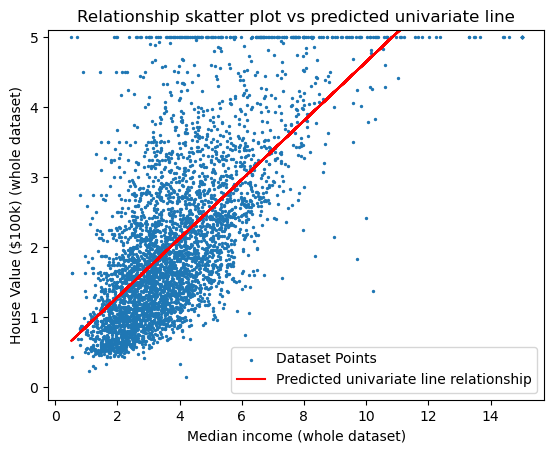

In [118]:
plt.scatter(x_te, y_te, s=2, label="Dataset Points"); plt.xlabel("Median income (whole dataset)"); plt.ylabel("House Value ($100k) (whole dataset)"); plt.title("Relationship skatter plot vs predicted univariate line")
plt.plot(x_te, y_p/100000, "r", label="Predicted univariate line relationship"); plt.legend(); plt.ylim(top=5.1)
plt.show()

**TODO 5.3** Look carefully at the scatter plot. Name **two** features of the data that a straight
line cannot capture. What does $R^2$ tell you about how much of the variation in house values is
explained by income alone?

Some house values are capped at 500k so these values are not well represented by the line, for example the line extends past median income = 10 so would predict a much larger house value than the house values that exist there since they are capped and the line doesn't factor this in. Another feature is how it appears as if a lot of the points cluster into one large group with other values fanning off of it. This causes 2 main issues, one being that the larger group is more ifluencial on values of theta so the more spread out values will be significantly less well represented. Another issue might be that perhaps the main group should be considered individually as the appearance of direction the main group follows is slightly different to the line as the fanned out values have affected the overall gradient. R2 is only 0.447 which is significant but the remaining error is substantial, the value inidactes a moderate relationship between the predicted data and the testing data. It may be used as a useful signal but since only 2 features are showcased the model is still incomplete and likely not much better than a baseline model.

## 6. Extension: stochastic and mini-batch gradient descent
Batch gradient descent uses all $m$ examples for every update. **Stochastic** GD uses one
random example per update; **mini-batch** GD uses a small random batch (e.g. 32).
Implement mini-batch GD (one *epoch* = one pass through a shuffled training set) and compare the
cost after each epoch with batch GD on the housing data. Compare with `sklearn.linear_model.SGDRegressor`.

In [ ]:
# YOUR CODE HERE

## Lab report checklist (Practical 3)
1. Your final $\theta_0, \theta_1$ on the synthetic data from gradient descent, the closed form and scikit-learn (table).
2. The learning-rate figure, with your explanation of what goes wrong when $\alpha$ is too small or too large.
3. Test-set RMSE, MAE and $R^2$ for the housing model, and a plot of the fitted line.
4. Your answer to 5.3: the limitations of a univariate linear model on this data.